# Tổng quan kinh doanh

| # | Câu hỏi |
|---|---|
| 1 | Số liệu thống kê doanh thu, số đơn, khách hàng, người bán, chất lượng phục vụ của doanh nghiêp? | 
| 2 | Doanh thu đi lên hay đang chững lại? Có giai đoạn nào tăng hay giảm bất thường không?| 
| 3 | Doanh thu đến từ phân khúc khách hàng nào?  | 
| 4 | Chất lượng phục vụ hiện đang đi lên hay đi xuống? | 

### Quy ước
- **Đơn hợp lệ** = đơn có sản phẩm và trạng thái khác `canceled` / `unavailable`. Mọi chỉ số doanh thu chỉ tính đơn hợp lệ.
- **Doanh thu (GMV)** = `price + freight_value` (BRL). **AOV** = GMV / số đơn hợp lệ. **Khách hàng** = `customer_unique_id`.
- **Đơn mất** = đơn `canceled` hoặc `unavailable` / tổng số đơn được đặt.
- **Khách mới** trong một kỳ = khách có đơn hợp lệ **đầu tiên** (trong toàn bộ dữ liệu) rơi vào kỳ đó; các đơn còn lại là **đơn của khách cũ**.
- **Đúng hạn** = đơn đã giao, ngày giao thực tế ≤ ngày hứa giao. **Không hài lòng** = đơn có ít nhất một review 1–2★.
- **Kỳ so sánh (YoY):** kỳ này = 01 → tháng báo cáo của năm mới nhất, so với cùng các tháng năm trước. Tháng báo cáo = tháng mới nhất có số đơn
  hợp lệ ≥ 10% tháng cao nhất (bỏ các tháng cuối chỉ có vài chục đơn); kỳ được suy ra từ dữ liệu trong `common.connect()` và in ở §0.
  Với dữ liệu hiện tại: 01–08/2018 so với 01–08/2017; biểu đồ theo tháng dùng 01/2017 → 08/2018.

## 0. Kết nối lakehouse & nạp dữ liệu Silver

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from common import *

con, P = connect()   # order_base + kỳ phân tích P
apply_theme()
C_PREV, C_CUR = C_GREY, C_MAIN   # màu năm trước / năm nay
REVIEW_TARGET = 4.0              # ngưỡng điểm review tham chiếu ở §4

Kỳ này 01–08/2018 | cùng kỳ 01–08/2017 | xu hướng 01/2017–08/2018 | 98,059 đơn, 96,817 đơn hợp lệ


### Tạo bảng phân tích
- `order_base` (tạo sẵn trong `connect()`): **1 dòng / đơn hàng** (mọi trạng thái): thời gian mua, trạng thái, cờ đơn mất `is_lost`, cờ đơn hợp lệ `is_valid`,
  khách, GMV, phí ship, số sản phẩm, điểm review, cờ không hài lòng, thời gian giao, cờ giao trễ.
- `sales`: view các **đơn hợp lệ** của `order_base`.
- `item_exec`: **1 dòng / sản phẩm trong đơn hợp lệ**, kèm người bán. Chỉ dùng để đếm người bán có đơn trong bảng KPI.

In [2]:
con.execute("CREATE OR REPLACE TABLE sales AS SELECT * FROM order_base WHERE is_valid = 1")
con.execute("""
CREATE OR REPLACE TABLE item_exec AS
SELECT i.order_key, i.seller_key, s.purchase_year, s.purchase_mon
FROM fact_order_items i JOIN sales s ON s.order_key = i.order_key
""")
print(q("""SELECT (SELECT count(*) FROM order_base) AS all_orders, (SELECT count(*) FROM sales) AS valid_orders,
                  (SELECT count(*) FROM item_exec) AS valid_items,
                  (SELECT min(purchase_month) FROM sales) AS first_month, (SELECT max(purchase_month) FROM sales) AS last_month""")
      .to_string(index=False))

 all_orders  valid_orders  valid_items first_month last_month
      98059         96817       110500  2016-09-01 2018-09-01


## 1. Bảng KPI điều hành
*Câu hỏi: "Số liệu thống kê doanh thu, số đơn, khách hàng, người bán, chất lượng phục vụ của doanh nghiêp?"*

In [3]:
def kpis(where: str) -> dict:
    sales_kpi = q(f"""SELECT sum(gmv) AS gmv, count(*) AS orders, count(DISTINCT customer_unique_id) AS customers,
                             avg(gmv) AS aov, sum(freight_value) / sum(gmv) AS freight_share,
                             avg(review_score) AS avg_review, avg(is_negative) AS negative_rate,
                             1 - avg(is_late) AS on_time_rate, avg(delivery_days) FILTER (WHERE is_late IS NOT NULL) AS delivery_days
                      FROM sales WHERE {where}""").iloc[0].to_dict()
    lost_kpi = q(f"SELECT avg(is_lost) AS lost_rate FROM order_base WHERE {where}").iloc[0].to_dict()
    seller_kpi = q(f"SELECT count(DISTINCT seller_key) AS sellers FROM item_exec WHERE {where}").iloc[0].to_dict()
    # Khách mua ≥ 2 đơn trong cùng kỳ
    repeat_kpi = q(f"""SELECT avg(CAST(n >= 2 AS INTEGER)) AS repeat_rate FROM
                       (SELECT customer_unique_id, count(*) AS n FROM sales WHERE {where} GROUP BY 1)""").iloc[0].to_dict()
    return {**sales_kpi, **lost_kpi, **seller_kpi, **repeat_kpi}

KPIS = [
    Kpi("gmv", "Doanh thu GMV (BRL)", "{:,.0f}", "pct"),
    Kpi("orders", "Số đơn hợp lệ", "{:,.0f}", "pct"),
    Kpi("customers", "Số khách hàng", "{:,.0f}", "pct"),
    Kpi("aov", "AOV (BRL)", "{:,.2f}", "pct"),
    Kpi("sellers", "Người bán có đơn", "{:,.0f}", "pct"),
    Kpi("repeat_rate", "% khách mua ≥2 đơn", "{:.2%}", "pp"),
    Kpi("avg_review", "Điểm review TB", "{:.2f}", "abs"),
    Kpi("negative_rate", "% đơn không hài lòng", "{:.1%}", "pp"),
    Kpi("on_time_rate", "% giao đúng hạn", "{:.1%}", "pp"),
    Kpi("delivery_days", "Số ngày giao TB", "{:.1f}", "abs"),
    Kpi("lost_rate", "% đơn mất (hủy/hết hàng)", "{:.2%}", "pp"),
    Kpi("freight_share", "Phí ship / GMV", "{:.1%}", "pp"),
]
print(kpi_table(KPIS, kpis, P).to_string())

                             Toàn kỳ 01–08/2017 01–08/2018  Thay đổi YoY
Chỉ số                                                                  
Doanh thu GMV (BRL)       15,526,006  3,564,588  8,398,428       +135.6%
Số đơn hợp lệ                 96,817     22,478     52,255       +132.5%
Số khách hàng                 93,664     21,858     51,098       +133.8%
AOV (BRL)                     160.36     158.58     160.72         +1.3%
Người bán có đơn               3,042      1,208      2,344        +94.0%
% khách mua ≥2 đơn             3.02%      2.58%      2.10%  -0.48 điểm %
Điểm review TB                  4.12       4.18       4.11         -0.07
% đơn không hài lòng           13.9%      12.0%      14.3%  +2.21 điểm %
% giao đúng hạn                93.2%      96.5%      92.1%  -4.38 điểm %
Số ngày giao TB                 12.2       11.7       11.8         +0.11
% đơn mất (hủy/hết hàng)       1.26%      1.77%      0.87%  -0.90 điểm %
Phí ship / GMV                 14.2%      13.8%    


> **🔎 Kết quả chính**
> - Toàn kỳ: **15,74 triệu BRL** GMV từ 98.199 đơn hợp lệ của 94.983 khách và 3.053 người bán, AOV **160 BRL**.
> - 01–08/2018 so với cùng kỳ 2017: **các chỉ số quy mô đều tăng khoảng +140%** (GMV +140,4%, đơn +137,3%, khách +138,6%), còn **AOV gần như đứng yên (+1,3%)**.
>   Số người bán chỉ tăng +94%.
> - **Các chỉ số chất lượng đều giảm**: % giao đúng hạn **−4,2 điểm %** (96,5% → 92,3%), % đơn không hài lòng **+2,1 điểm %** (12,1% → 14,1%), điểm review 4,18 → 4,11.
>   Tỷ lệ khách mua ≥2 đơn trong kỳ cũng giảm (2,60% → 2,12%).
> - Điểm sáng: **% đơn mất** (hủy/hết hàng) giảm một nửa, 1,77% → 0,85%.


## 2. Xu hướng doanh thu theo tháng
*Câu hỏi: "Doanh thu đi lên, đi ngang hay đang chững lại? Có giai đoạn nào tăng hay giảm bất thường không?"*

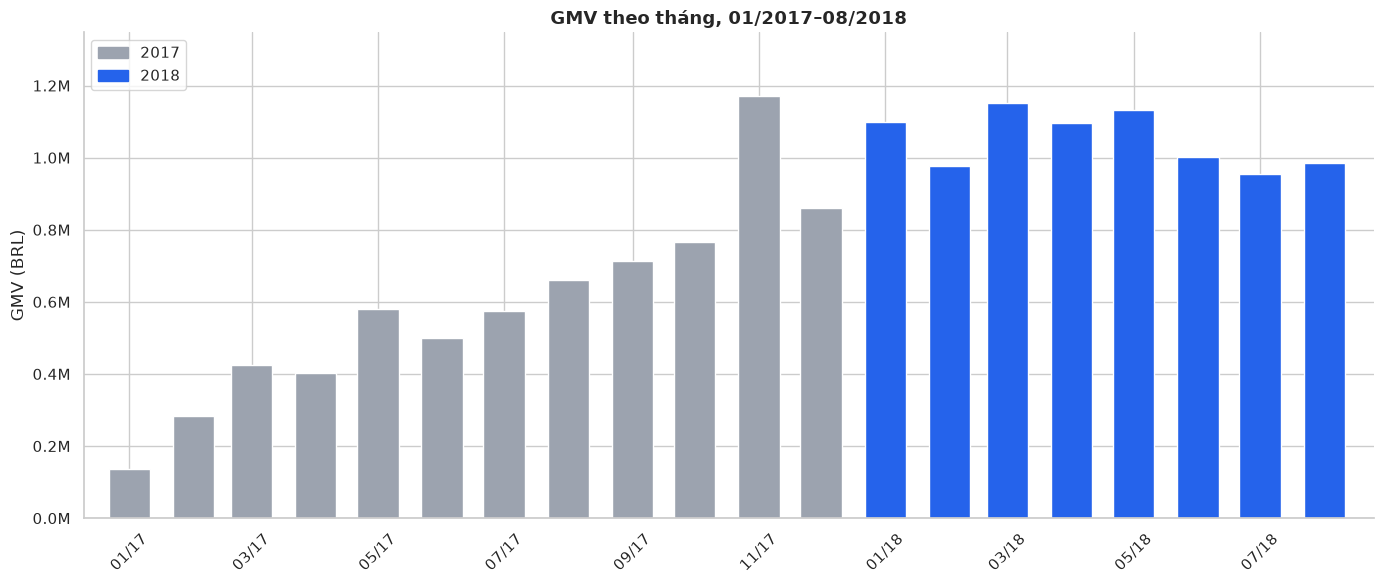

Các mốc GMV: 01/2017: 0.14M, 10/2017: 0.76M, 11/2017: 1.17M, 12/2017: 0.86M
Các mốc số đơn: 01/2017: 786, 10/2017: 4,547, 11/2017: 7,420, 12/2017: 5,613
Tháng cao nhất: 11/2017 (1.17M); GMV cao nhất 2018: 1.15M
Tháng nhiều đơn nhất: 11/2017 (7,420 đơn); cao nhất 2018: 7,166 đơn


In [4]:
monthly = q(f"""SELECT purchase_month AS month, sum(gmv) AS gmv, count(*) AS orders
                FROM sales WHERE {P.in_period} GROUP BY 1 ORDER BY 1""")
monthly["month"] = pd.to_datetime(monthly.month)

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(monthly.month, monthly.gmv, width=20, color=[C_CUR if m.year == P.year_cur else C_PREV for m in monthly.month])
brl_axis(ax); ax.set_ylabel("GMV (BRL)"); ax.set_ylim(0, monthly.gmv.max() * 1.15)
ax.legend(handles=[Patch(color=C_PREV, label=str(P.year_prev)), Patch(color=C_CUR, label=str(P.year_cur))], loc="upper left")
ax.set_title(f"GMV theo tháng, {P.label_trend}")
month_axis(ax); ax.set_xlim(monthly.month.iloc[0] - pd.Timedelta(days=22), monthly.month.iloc[-1] + pd.Timedelta(days=24))
plt.tight_layout(); plt.show()

# Các mốc: tháng đầu kỳ và tháng GMV cao nhất cùng 2 tháng liền kề
gmv_by_month = monthly.set_index("month")
peak = gmv_by_month.gmv.idxmax()
milestones = [gmv_by_month.index[0], peak - pd.DateOffset(months=1), peak, peak + pd.DateOffset(months=1)]
cur_year = gmv_by_month.loc[str(P.year_cur)]
print("Các mốc GMV:", ", ".join(f"{m:%m/%Y}: {gmv_by_month.gmv[m] / 1e6:.2f}M" for m in milestones))
print("Các mốc số đơn:", ", ".join(f"{m:%m/%Y}: {gmv_by_month.orders[m]:,}" for m in milestones))
print(f"Tháng cao nhất: {peak:%m/%Y} ({gmv_by_month.gmv.max() / 1e6:.2f}M); "
      f"GMV cao nhất {P.year_cur}: {cur_year.gmv.max() / 1e6:.2f}M")
print(f"Tháng nhiều đơn nhất: {gmv_by_month.orders.idxmax():%m/%Y} ({gmv_by_month.orders.max():,} đơn); "
      f"cao nhất {P.year_cur}: {cur_year.orders.max():,} đơn")

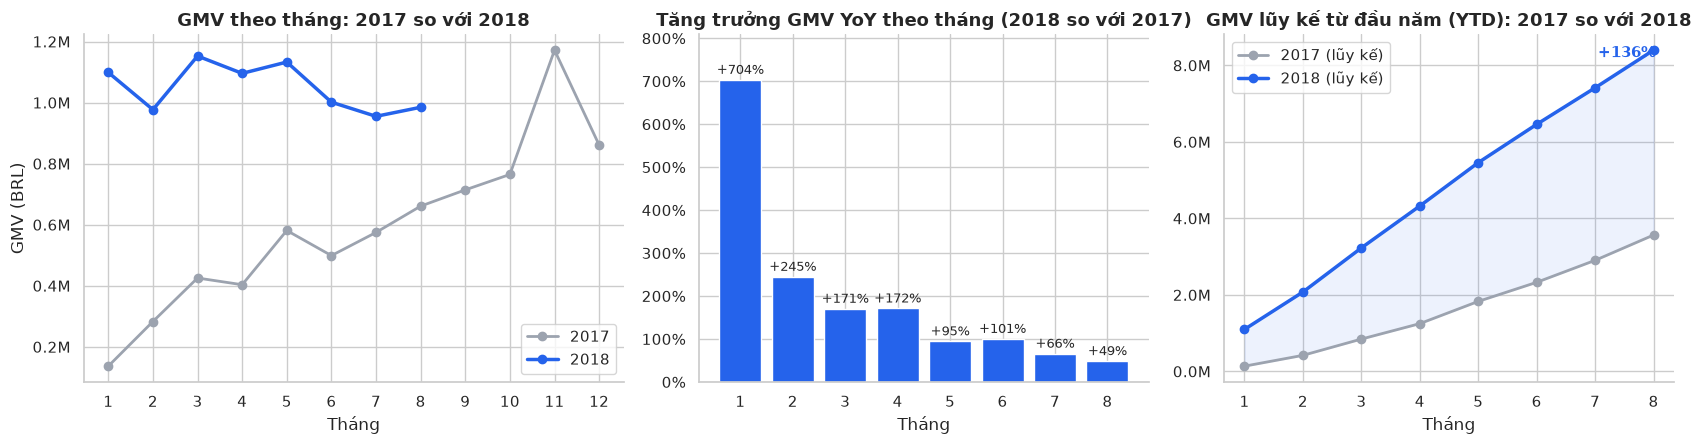

GMV TB/tháng 01–04/2018: 1,081,057 | 05–08/2018: 1,018,550 (-5.8%)
Đơn TB/tháng 01–04/2018: 6,866 | 05–08/2018: 6,197
YoY theo tháng: T1: +704%, T2: +245%, T3: +171%, T4: +172%, T5: +95%, T6: +101%, T7: +66%, T8: +49%


In [5]:
# So sánh cùng tháng năm trước vs năm nay và tăng trưởng YoY theo từng tháng
by_year_month = monthly.assign(y=monthly.month.dt.year, m=monthly.month.dt.month)
prev = by_year_month[by_year_month.y == P.year_prev].set_index("m")
cur = by_year_month[by_year_month.y == P.year_cur].set_index("m")
yoy_m = cur.gmv / prev.gmv.reindex(cur.index) - 1
cur_months = range(1, P.last_mon + 1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.2, 1, 1]})
ax1.plot(prev.index, prev.gmv, color=C_PREV, marker="o", lw=2, label=str(P.year_prev))
ax1.plot(cur.index, cur.gmv, color=C_CUR, marker="o", lw=2.5, label=str(P.year_cur))
ax1.set_xticks(range(1, 13)); brl_axis(ax1); ax1.legend(); ax1.set_xlabel("Tháng")
ax1.set_title(f"GMV theo tháng: {P.year_prev} so với {P.year_cur}"); ax1.set_ylabel("GMV (BRL)")

yoy_bars = ax2.bar(yoy_m.index, yoy_m.values, color=C_MAIN)
ax2.bar_label(yoy_bars, labels=[f"{v:+.0%}" for v in yoy_m.values], padding=2, fontsize=9)
pct_axis(ax2); ax2.set_xticks(cur_months); ax2.set_xlabel("Tháng"); ax2.set_ylim(0, yoy_m.max() * 1.15)
ax2.set_title(f"Tăng trưởng GMV YoY theo tháng ({P.year_cur} so với {P.year_prev})")

cum_prev, cum_cur = prev.gmv.loc[:P.last_mon].cumsum(), cur.gmv.cumsum()
ax3.plot(cum_prev.index, cum_prev, color=C_PREV, marker="o", lw=2, label=f"{P.year_prev} (lũy kế)")
ax3.plot(cum_cur.index, cum_cur, color=C_CUR, marker="o", lw=2.5, label=f"{P.year_cur} (lũy kế)")
ax3.fill_between(cum_cur.index, cum_prev.values, cum_cur.values, color=C_CUR, alpha=0.08)
ax3.annotate(f"{cum_cur.iloc[-1] / cum_prev.iloc[-1] - 1:+.0%}", (P.last_mon, cum_cur.iloc[-1]), xytext=(-40, -5),
             textcoords="offset points", fontsize=11, fontweight="bold", color=C_CUR)
brl_axis(ax3); ax3.set_xticks(cur_months); ax3.set_xlabel("Tháng"); ax3.legend(loc="upper left")
ax3.set_title(f"GMV lũy kế từ đầu năm (YTD): {P.year_prev} so với {P.year_cur}")
plt.tight_layout(); plt.show()

# Nửa đầu và nửa sau của kỳ này
half = P.last_mon // 2
early, late = cur.loc[1:half], cur.loc[half + 1:P.last_mon]
early_label, late_label = f"01–{half:02d}/{P.year_cur}", f"{half + 1:02d}–{P.last_mon:02d}/{P.year_cur}"
print(f"GMV TB/tháng {early_label}: {early.gmv.mean():,.0f} | {late_label}: {late.gmv.mean():,.0f} "
      f"({late.gmv.mean() / early.gmv.mean() - 1:+.1%})")
print(f"Đơn TB/tháng {early_label}: {early.orders.mean():,.0f} | {late_label}: {late.orders.mean():,.0f}")
print("YoY theo tháng:", ", ".join(f"T{m}: {v:+.0%}" for m, v in yoy_m.items()))


> **🔎 Kết quả chính**
> - Năm 2017 **tăng tốc**: GMV từ 0,14 triệu (01/2017) lên 0,76 triệu (10/2017), đạt **đỉnh 1,17 triệu ở 11/2017 (Black Friday, 7.421 đơn)**, rồi lùi về 0,86 triệu ở 12/2017.
> - **Năm 2018 đi ngang, hơi giảm**: GMV TB/tháng 01–04/2018 là 1,10 triệu, 05–08/2018 là 1,05 triệu (**−4,3%**); số đơn TB/tháng 6.974 → 6.408. Không tháng nào vượt đỉnh Black Friday 2017.
> - **YoY theo tháng giảm dần**: +705% (T1) → +171% (T3) → +97% (T5) → **+51% (T8)**. Con số "+140% YTD" chủ yếu phản ánh nền thấp của 2017, không phải đà tăng hiện tại.


## 3. Xác định tệp khách hàng
*Câu hỏi: "Doanh thu đến từ phân khúc khách hàng nào?"*

Phân khúc theo **RFM**, mỗi khách (`customer_unique_id`) được chấm 3 điểm 1–5. Ngày chốt số liệu = ngày mua cuối cùng trong dữ liệu + 1 = **04/09/2018**.
- **R** (Recency) = số ngày từ lần mua cuối của khách tới ngày chốt; mua càng gần đây điểm càng cao.
  Ngưỡng là **ngũ phân vị** của số ngày (mỗi mức ≈ 20% khách).
- **F** (Frequency) = số đơn hợp lệ của khách. ≈97% khách chỉ mua 1 đơn nên mọi ngưỡng ngũ phân vị đều bằng 1 → vẫn chia **5 mức**
  nhưng theo **ngưỡng cố định** số đơn.
- **M** (Monetary) = tổng GMV (giá + phí ship) của khách; chi càng nhiều điểm càng cao. Ngưỡng là **ngũ phân vị** của tổng GMV.

| Điểm | R: số ngày từ lần mua cuối | F: số đơn | M: tổng GMV (BRL) |
|---|---|---|---|
| **5** | ≤ 99 ngày | ≥ 5 đơn | > 209,11 |
| **4** | 100 – 183 ngày | 4 đơn | > 133,05 – 209,11 |
| **3** | 184 – 274 ngày | 3 đơn | > 87,50 – 133,05 |
| **2** | 275 – 389 ngày | 2 đơn | > 55,36 – 87,50 |
| **1** | ≥ 390 ngày | 1 đơn | ≤ 55,36 |

*Ngưỡng R và M tính lại mỗi lần chạy từ dữ liệu; số trên là kết quả với dữ liệu hiện tại, bảng `rfm_range` bên dưới in ngưỡng thực tế.*

Bảng `customer_rfm` và quy tắc phân khúc do `create_customer_rfm()` của `common/rfm.py` tạo, dùng chung với `customer_behaviour` §3 nên số liệu hai notebook khớp nhau
(xét lần lượt từ trên xuống, khách thuộc quy tắc đầu tiên khớp; 6 phân khúc phủ hết mọi khách):

| Phân khúc | Quy tắc | Ý nghĩa hành động |
|---|---|---|
| Champions | F ≥ 2 và R ≥ 4 | Mua lại & mới mua gần đây → chương trình VIP/thành viên |
| Loyal – cần giữ chân | F ≥ 2 và R ≤ 3 | Từng mua lại nhưng lâu không quay lại → win-back ưu tiên |
| Khách mới | F = 1, R ≥ 4 | Mới mua lần đầu gần đây → kích hoạt đơn thứ 2 (cross-sell, freeship theo ngưỡng) |
| Cần nuôi dưỡng | F = 1, R = 3 | Đã một thời gian chưa quay lại → email/remarketing |
| Giá trị cao sắp mất | F = 1, R ≤ 2, M ≥ 4 | Chi nhiều nhưng lâu không mua → ưu đãi win-back |
| Đã rời bỏ | F = 1, R ≤ 2, M ≤ 3 | Giá trị thấp, lâu không mua → chi phí thấp nhất |


In [6]:
# Bảng khách hàng: 1 dòng / khách, chấm điểm R-F-M (1-5) và gán phân khúc (common.create_customer_rfm)
rfm = create_customer_rfm()

# Ngưỡng thực tế của từng mức điểm
rfm_range = pd.concat([
    q(f"""SELECT '{d}' AS dim, {d} AS score, min({c}) AS min_value, max({c}) AS max_value, count(*) AS customers
          FROM customer_rfm GROUP BY 1, 2""")
    for d, c in [("R", "recency_days"), ("F", "frequency"), ("M", "monetary")]
]).sort_values(["dim", "score"]).reset_index(drop=True)
print(f"Ngày chốt số liệu: {rfm.snapshot} | Số khách: {scalar('SELECT count(*) FROM customer_rfm'):,}")
rfm_range.round(2)

Ngày chốt số liệu: 2018-09-04 | Số khách: 93,664


,dim,score,min_value,max_value,customers
0,F,1,1.00,1.00,90834
1,F,2,2.00,2.00,2599
2,F,3,3.00,3.00,184
3,F,4,4.00,4.00,28
4,F,5,5.00,16.00,19
5,M,1,9.59,55.31,18734
6,M,2,55.32,87.41,18733
7,M,3,87.42,133.05,18737
8,M,4,133.06,209.15,18727
9,M,5,209.16,13664.08,18733


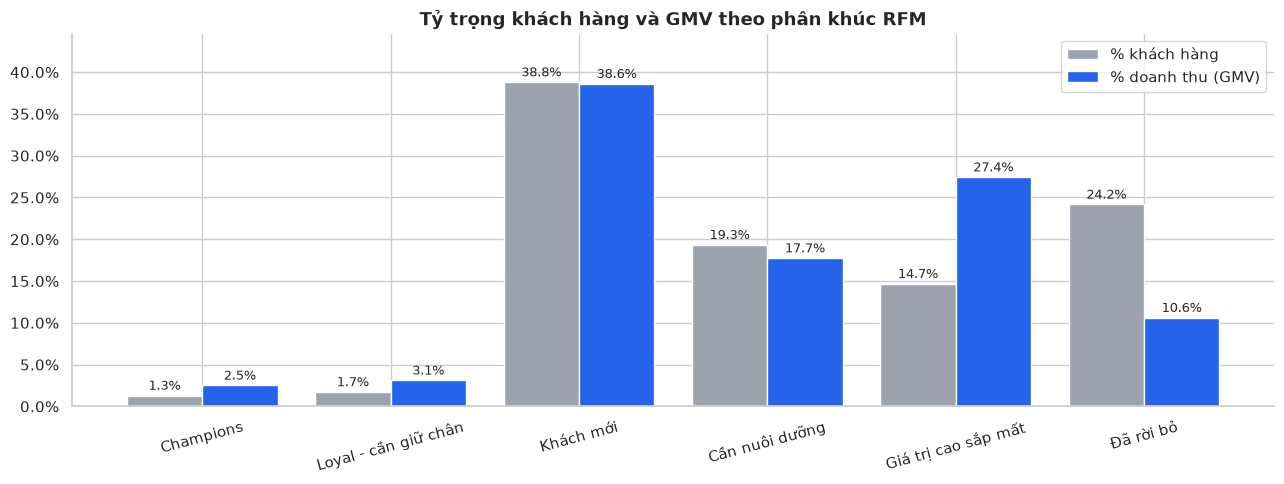

,F,customers,gmv,gmv_per_customer,gmv_share
0,1,90834,14653824.87,161.325,0.944
1,2,2599,756710.22,291.154,0.049
2,3,184,78877.02,428.679,0.005
3,4,28,21615.84,771.994,0.001
4,5,19,14978.46,788.340,0.001


,segment,customers,gmv,avg_recency_days,avg_orders,gmv_per_customer,customer_share,gmv_share
0,Champions,1216,388708.09,97.285,2.16,319.661,0.013,0.025
1,Loyal - cần giữ chân,1614,483473.45,329.310,2.08,299.550,0.017,0.031
2,Khách mới,36342,5993550.07,98.657,1.00,164.921,0.388,0.386
3,Cần nuôi dưỡng,18117,2753710.68,229.347,1.00,151.996,0.193,0.177
4,Giá trị cao sắp mất,13738,4258923.76,402.838,1.00,310.010,0.147,0.274
5,Đã rời bỏ,22637,1647640.36,403.672,1.00,72.785,0.242,0.106


In [7]:
# Doanh thu đến từ phân khúc nào: % khách vs % doanh thu
seg = q("""
SELECT segment, count(*) AS customers, sum(monetary) AS gmv,
       avg(recency_days) AS avg_recency_days, avg(frequency) AS avg_orders, avg(monetary) AS gmv_per_customer
FROM customer_rfm GROUP BY 1""")
seg = ordered(seg, "segment", SEG_ORDER).fillna(0)
seg["customer_share"] = seg.customers / seg.customers.sum()
seg["gmv_share"] = seg.gmv / seg.gmv.sum()

fig, ax = plt.subplots(figsize=(13, 5))
grouped_bar(ax, seg.segment, {"% khách hàng": (seg.customer_share, C_GREY), "% doanh thu (GMV)": (seg.gmv_share, C_MAIN)},
            value_fmt="{:.1%}")
ax.tick_params(axis="x", rotation=15); pct_axis(ax); ax.set_ylim(0, seg[["customer_share", "gmv_share"]].max().max() * 1.15)
ax.set_title("Tỷ trọng khách hàng và GMV theo phân khúc RFM")
plt.tight_layout(); plt.show()

# Mỗi điểm F đóng góp bao nhiêu doanh thu
f_mix = q('SELECT F AS "F", count(*) AS customers, sum(monetary) AS gmv, avg(monetary) AS gmv_per_customer FROM customer_rfm GROUP BY 1 ORDER BY 1')
f_mix["gmv_share"] = f_mix.gmv / f_mix.gmv.sum()
display(f_mix.round(3))
seg.round(3)

## 4. Chất lượng phục vụ
*Câu hỏi: "Chất lượng phục vụ hiện tại đang như thế nào?"*

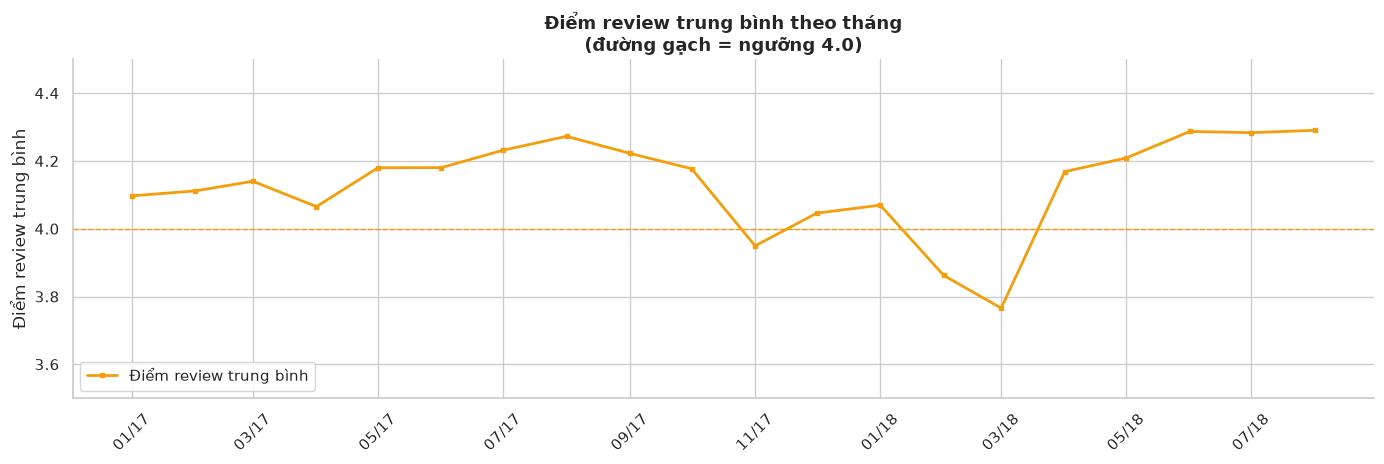

Tương quan theo tháng (01/2017–08/2018; orders_placed = mọi đơn được đặt, kể cả đơn mất):
   orders_placed vs on_time_rate  : -0.55
      orders_mom vs on_time_rate  : +0.08
    on_time_rate vs avg_review    : +0.88
   delivery_days vs negative_rate : +0.89

3 tháng kém nhất về % đúng hạn:
            orders_placed  on_time_rate  avg_review  negative_rate  delivery_days  promised_days
month                                                                                           
2018-03-01           7209         0.810       3.766          0.224         15.870         21.666
2018-02-01           6716         0.858       3.862          0.199         16.518         24.162
2017-11-01           7543         0.876       3.949          0.177         14.699         22.197

6 tháng nhiều đơn nhất (kiểm tra giả thuyết 'quá tải → giao trễ'):
            orders_placed  on_time_rate  avg_review  negative_rate  delivery_days  promised_days
month                                                      

 year  avg_review  on_time_rate  negative_rate  actual_days  promised_days
 2017       4.182         0.965          0.120       11.675         25.026
 2018       4.108         0.921          0.143       11.788         22.438


In [8]:
health = q(f"""SELECT purchase_month AS month, count(*) AS orders_placed, avg(is_lost) AS lost_rate
               FROM order_base WHERE {P.in_period} GROUP BY 1""")
health = health.merge(q(f"""SELECT purchase_month AS month, avg(review_score) AS avg_review, avg(is_negative) AS negative_rate,
                                   1 - avg(is_late) AS on_time_rate,
                                   avg(delivery_days) FILTER (WHERE is_late IS NOT NULL) AS delivery_days,
                                   avg(estimated_delivery_days) FILTER (WHERE is_late IS NOT NULL) AS promised_days
                            FROM sales WHERE {P.in_period} GROUP BY 1"""), on="month")
health["month"] = pd.to_datetime(health.month)
health = health.sort_values("month")

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(health.month, health.avg_review, color=C_ACCENT, marker="s", ms=3.5, lw=2, label="Điểm review trung bình")
ax.axhline(REVIEW_TARGET, color=C_ACCENT, ls="--", lw=1)
ax.set_ylim(REVIEW_TARGET - 0.5, REVIEW_TARGET + 0.5); ax.set_ylabel("Điểm review trung bình")
month_axis(ax)
ax.legend(loc="lower left")
ax.set_title(f"Điểm review trung bình theo tháng\n(đường gạch = ngưỡng {REVIEW_TARGET:.1f})")
plt.tight_layout(); plt.show()

health_by_month = health.set_index("month")
health_by_month["orders_mom"] = health_by_month.orders_placed.pct_change()
HEALTH_COLS = ["orders_placed", "on_time_rate", "avg_review", "negative_rate", "delivery_days", "promised_days"]
print(f"Tương quan theo tháng ({P.label_trend}; orders_placed = mọi đơn được đặt, kể cả đơn mất):")
for x_col, y_col in [("orders_placed", "on_time_rate"), ("orders_mom", "on_time_rate"), ("on_time_rate", "avg_review"),
                     ("delivery_days", "negative_rate")]:
    print(f"  {x_col:>14} vs {y_col:<14}: {health_by_month[x_col].corr(health_by_month[y_col]):+.2f}")
print("\n3 tháng kém nhất về % đúng hạn:")
print(health_by_month.nsmallest(3, "on_time_rate")[HEALTH_COLS].round(3).to_string())
print("\n6 tháng nhiều đơn nhất (kiểm tra giả thuyết 'quá tải → giao trễ'):")
print(health_by_month.nlargest(6, "orders_placed")[HEALTH_COLS].round(3).to_string())
worst_cur = health_by_month.loc[str(P.year_cur)].on_time_rate.idxmin()
print(f"\nGiai đoạn phục hồi sau tháng đúng hạn kém nhất {P.year_cur} ({worst_cur:%m/%Y}):")
print(health_by_month.loc[worst_cur + pd.DateOffset(months=1):, HEALTH_COLS].round(3).to_string())
print(f"\nSo sánh cùng kỳ {P.label_prev} và {P.label_cur} (đơn hợp lệ):")
print(q(f"""SELECT purchase_year AS year, avg(review_score) AS avg_review, 1 - avg(is_late) AS on_time_rate,
                   avg(is_negative) AS negative_rate,
                   avg(delivery_days) FILTER (WHERE is_late IS NOT NULL) AS actual_days,
                   avg(estimated_delivery_days) FILTER (WHERE is_late IS NOT NULL) AS promised_days
            FROM sales WHERE ({P.prev}) OR ({P.cur}) GROUP BY 1 ORDER BY 1""").round(3).to_string(index=False))


> **🔎 Kết quả chính**
> - Có **3 tháng "khủng hoảng" chất lượng**: 11/2017 (đúng hạn 87,6%, review 3,95), **02/2018** (85,9%, 3,86) và **03/2018** (81,0%, 3,77, 22,4% đơn không hài lòng); số ngày giao vọt lên 15–17 ngày (bình thường 11–12).
> - **Số đơn cao không đủ giải thích**: tương quan số đơn ↔ % đúng hạn chỉ −0,52; 01/2018, 04/2018, 05/2018 nhiều đơn vẫn đúng hạn 93–95%. Dữ liệu không cho biết nguyên nhân của 02–03/2018.
> - Các chỉ số chất lượng đi cùng nhau rất chặt: % đúng hạn ↔ điểm review **+0,87**, số ngày giao ↔ % không hài lòng **+0,89**.
> - So cùng kỳ 01–08, số ngày giao gần như giữ nguyên (12,2 → 12,1) nhưng **thời gian hứa giao rút từ 26,0 xuống 23,4 ngày**, kéo % đúng hạn từ 96,5% xuống 92,3%: khoảng đệm hẹp khiến giao chậm dễ thành giao trễ.
> - Từ 04/2018 **phục hồi rõ**: số ngày giao 11,4 → 7,7 (08/2018), % không hài lòng 12,8% → 10,0%, review 4,17 → 4,29, mức tốt nhất toàn kỳ.


In [9]:
con.close()